
# Task B3: Predicting Star Ratings of E-Commerce Clothing Reviews

## 1. Introduction

This project focuses on predicting customer star ratings (1–5) from women's e-commerce clothing reviews using supervised machine learning.

The dataset contains textual reviews, numerical information, and categorical product features. The objective is to build models that can predict customer ratings based on these inputs.

## 2. Problem Statement

This is a supervised multi-class ordinal classification problem. The input consists of customer review text, customer age, positive feedback count, and product categories. The target variable is the customer rating, ranging from 1 to 5.

The primary evaluation metric is Macro-F1. Additional metrics include accuracy, weighted-F1, per-class recall, confusion matrix, and ordinal MAE.

## 3. Dataset

Dataset: Women's E-Commerce Clothing Reviews

Source: Kaggle  
https://www.kaggle.com/datasets/nicapotato/womens-ecommerce-clothing-reviews

## 4. Methodology

The project will include data cleaning, exploratory data analysis, text processing using TF-IDF, categorical encoding, numerical preprocessing, model training, evaluation, and feature ablation.

Three feature settings will be compared:
- Structured features only
- Text features only
- Combined text and structured features


## Assignment Workflow Diagram and Project Roadmap

Below is the structured roadmap of our entire machine learning pipeline. It shows exactly how our data flows from raw files into clean, actionable business predictions.

```
[1. Raw CSV Dataset]
       │
       ▼
[2. Data Cleaning] ─────────► Handled Nulls & Combined (Title + Review Text)
       │
       ▼
[3. Visual EDA] ────────────► Analyzed Ratings, Word Counts, Age & Departments
       │
       ▼
[4. Stratified Split] ──────► 70% Train / 15% Validation / 15% Test
       │
       ▼
[5. Preprocessing Pipeline] ─► Scaling (Numerical) + One-Hot (Categorical) + TF-IDF (Text)
       │
       ▼
[6. Model Selection] ───────► Compared 3 Models (Logistic Regression, Linear SVM, LightGBM)
       │                      with & without Class Balancing weights
       │
       ▼
[7. Feature Ablation] ──────► Tested representations: Structured-only vs. Text-only vs. Combined
       │
       ▼
[8. Sentiment Reframing] ───► Simplified 5-Class system into 3-Classes (Pos / Neu / Neg)
       │
       ▼
[9. Error Analysis] ────────► Diagnosed model failure points on real edge-case reviews
```

---

### Quick Overview of Steps

*   **Why Clean the Data?** Raw text has empty fields and split titles. We join them so our model reads full reviews.
*   **Why Stratify the Splits?** E-commerce reviews are highly imbalanced (mostly 5-star ratings). Stratifying ensures our Train, Val, and Test sets have the exact same percentage of happy/unhappy ratings.
*   **Why Use Three Feature Options?** We test if the model learns better from metadata (Age, Category), the review text itself, or both combined.
*   **Why Reframe into 3-Classes?** To give businesses a simple, actionable view (Happy, Average, or Angry customers) instead of confusing them with tiny differences between a 1 and 2-star rating.

# Section 1. Import Dataset

In [2]:
from google.colab import files
import pandas as pd
import io

# This will prompt you to select a file from your local machine
uploaded = files.upload()

# Once uploaded, you can load it into a pandas DataFrame
# (Make sure to replace 'Womens Clothing E-Commerce Reviews.csv' with the actual name of your file if it differs)
for filename in uploaded.keys():
    df = pd.read_csv(io.BytesIO(uploaded[filename]))
    print(f'Successfully loaded {filename}!')
    display(df.head())

Saving Womens Clothing E-Commerce Reviews.csv to Womens Clothing E-Commerce Reviews.csv
Successfully loaded Womens Clothing E-Commerce Reviews.csv!


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


# Section 2. Import Libraries

In [3]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully!")
print("Random State:", RANDOM_STATE)

Libraries imported successfully!
Random State: 42



## 3. Dataset Overview

This section provides an initial overview of the dataset. We examine its dimensions, column names, data types, first few records, and statistical summary to understand the structure and characteristics of the data.


In [4]:

# 1. Dataset dimensions
print("Dataset Shape:", df.shape)

# 2. Column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Dataset information
print("\nDataset Information:")
df.info()

# 4. First five rows
print("\nFirst Five Rows:")
display(df.head())

# 5. Statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all"))


Dataset Shape: (23486, 11)

Column Names:
['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Unnamed: 0               23486 non-null  int64 
 1   Clothing ID              23486 non-null  int64 
 2   Age                      23486 non-null  int64 
 3   Title                    19676 non-null  object
 4   Review Text              22641 non-null  object
 5   Rating                   23486 non-null  int64 
 6   Recommended IND          23486 non-null  int64 
 7   Positive Feedback Count  23486 non-null  int64 
 8   Division Name            23472 non-null  object
 9   Department Name          23472 non-null  object
 10  Class Name         

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses



Statistical Summary:


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
count,23486.000000,23486.000000,23486.000000,19676,22641,23486.000000,23486.000000,23486.000000,23472,23472,23472
unique,NaN,NaN,NaN,13993,22634,NaN,NaN,NaN,3,6,20
top,NaN,NaN,NaN,Love it!,Perfect fit and i've gotten so many compliment...,NaN,NaN,NaN,General,Tops,Dresses
freq,NaN,NaN,NaN,136,3,NaN,NaN,NaN,13850,10468,6319
mean,11742.500000,918.118709,43.198544,NaN,NaN,4.196032,0.822362,2.535936,NaN,NaN,NaN
std,6779.968547,203.298980,12.279544,NaN,NaN,1.110031,0.382216,5.702202,NaN,NaN,NaN
min,0.000000,0.000000,18.000000,NaN,NaN,1.000000,0.000000,0.000000,NaN,NaN,NaN
25%,5871.250000,861.000000,34.000000,NaN,NaN,4.000000,1.000000,0.000000,NaN,NaN,NaN
50%,11742.500000,936.000000,41.000000,NaN,NaN,5.000000,1.000000,1.000000,NaN,NaN,NaN
75%,17613.750000,1078.000000,52.000000,NaN,NaN,5.000000,1.000000,3.000000,NaN,NaN,NaN



## 4. Data Cleaning and Preprocessing

Data cleaning is an important step before training machine learning models. In this section, we identify and handle missing review text, remove empty reviews, and combine review titles with their corresponding review text.

The combined text will provide more information about customer opinions and help the models learn from the reviews more effectively.


In [5]:
# STEP 1: Copy dataset
df_clean = df.copy()

# Print shape and column list BEFORE combination
print("--- BEFORE COMBINING TITLE & TEXT ---")
print(f"Total columns: {df_clean.shape[1]}")
print("Columns present:", df_clean.columns.tolist())

# STEP 2: Show missing value count
print("Missing Values Before Cleaning:")
print(df_clean.isnull().sum())

# STEP 3: Handle empty review text
df_clean["Review Text"] = df_clean["Review Text"].fillna("").astype(str).str.strip()

# STEP 4: Remove rows where review text is totally empty
df_clean = df_clean[df_clean["Review Text"] != ""].copy()

# STEP 5: Handle empty titles
df_clean["Title"] = df_clean["Title"].fillna("").astype(str).str.strip()

# STEP 6: Combine "Title" and "Review Text" into a new column "Combined Review"
df_clean["Combined Review"] = (
    df_clean["Title"] + " " + df_clean["Review Text"]
).str.strip()

# Print shape and column list AFTER combination
print("--- AFTER COMBINING TITLE & TEXT we created Combined Review ---")
print(f"Total columns now: {df_clean.shape[1]}")
print("Columns present:", df_clean.columns.tolist())

# STEP 7: Show rows count change
print("Rows before cleaning:", df.shape[0])
print("Rows after cleaning:", df_clean.shape[0])

# STEP 8: Show missing values check after cleaning
print("Missing Values After Cleaning:")
print(df_clean.isnull().sum())

--- BEFORE COMBINING TITLE & TEXT ---
Total columns: 11
Columns present: ['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']
Missing Values Before Cleaning:
Unnamed: 0                    0
Clothing ID                   0
Age                           0
Title                      3810
Review Text                 845
Rating                        0
Recommended IND               0
Positive Feedback Count       0
Division Name                14
Department Name              14
Class Name                   14
dtype: int64
--- AFTER COMBINING TITLE & TEXT we created Combined Review ---
Total columns now: 12
Columns present: ['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name', 'Combined Review']
Rows before cleaning: 23486
Rows after cleaning: 22641
Missing Values Afte


## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the dataset before applying machine learning models.

In this section, we analyze the distribution of customer ratings, review lengths, customer ages, and ratings across different product departments. Visualizations are used to identify patterns, imbalances, and useful characteristics of the dataset.


In [6]:

# Calculate the number of words in each review
df_clean["Review Length"] = df_clean["Combined Review"].apply(
    lambda text: len(text.split())
)

# Display review length statistics
print("Review Length Statistics:")
display(df_clean["Review Length"].describe())

# Display sample reviews with their lengths
display(df_clean[["Combined Review", "Review Length"]].head())


Review Length Statistics:


,Review Length
count,22641.000000
mean,63.103131
std,29.088594
min,2.000000
25%,39.000000
50%,62.000000
75%,92.000000
max,121.000000


,Combined Review,Review Length
0,Absolutely wonderful - silky and sexy and comf...,8
1,Love this dress! it's sooo pretty. i happene...,62
2,Some major design flaws I had such high hopes ...,102
3,"My favorite buy! I love, love, love this jumps...",25
4,Flattering shirt This shirt is very flattering...,38



### 5.1 Distribution of Customer Ratings

This analysis examines how frequently each star rating appears in the dataset. It helps identify class imbalance and understand the distribution of customer satisfaction levels.


Rating Distribution Summary:


,Count,Percentage (%)
Rating,,
1,821,3.63
2,1549,6.84
3,2823,12.47
4,4908,21.68
5,12540,55.39


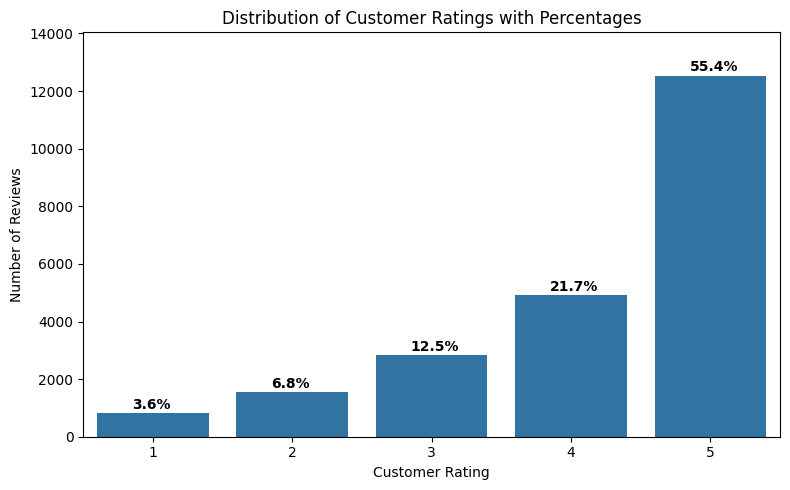

In [7]:
# Calculate counts and percentages for each rating
rating_counts = df_clean["Rating"].value_counts().sort_index()
rating_percentages = df_clean["Rating"].value_counts(normalize=True).sort_index() * 100

# Create a summary DataFrame for display
rating_summary = pd.DataFrame({
    "Count": rating_counts,
    "Percentage (%)": rating_percentages.round(2)
})

print("Rating Distribution Summary:")
display(rating_summary)

# Visualize rating distribution with percentage annotations
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df_clean, x="Rating")

total = len(df_clean)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2 - 0.15
    y = p.get_height() + 150
    ax.annotate(percentage, (x, y), fontsize=10, weight='bold')

plt.title("Distribution of Customer Ratings with Percentages")
plt.xlabel("Customer Rating")
plt.ylabel("Number of Reviews")
plt.ylim(0, max(rating_counts) + 1500)
plt.tight_layout()
plt.show()


### 5.2 Review Length Across Different Ratings

This analysis compares the length of customer reviews across different star ratings. It helps identify whether customers who give different ratings tend to write shorter or longer reviews.


Average Review Length by Rating:


,Review Length
Rating,
1,61.423873
2,65.337637
3,67.606801
4,66.463529
5,60.607974


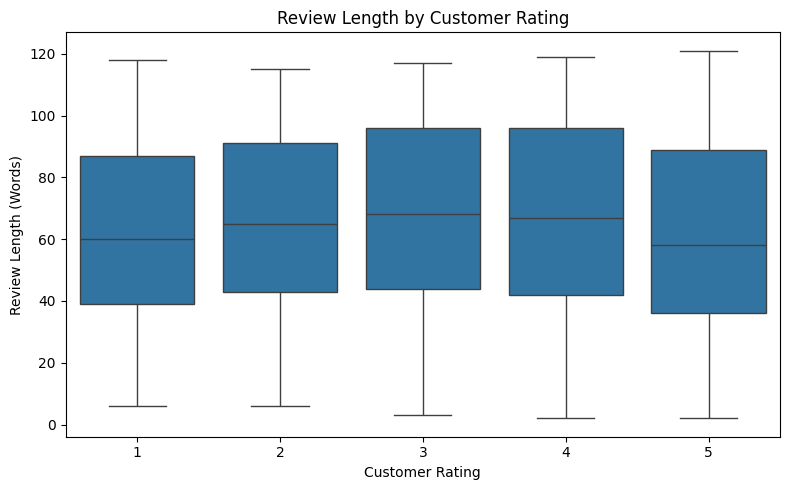

In [8]:

# Calculate average review length for each rating
review_length_by_rating = df_clean.groupby("Rating")["Review Length"].mean()

print("Average Review Length by Rating:")
display(review_length_by_rating)

# Visualize review length by rating
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="Rating", y="Review Length")

plt.title("Review Length by Customer Rating")
plt.xlabel("Customer Rating")
plt.ylabel("Review Length (Words)")
plt.tight_layout()
plt.show()


### 5.3 Initial EDA Observations

Here are the main things we found in our data:

* **Uneven Ratings (Class Imbalance)**: Most reviews are very positive. Rating 5 is the largest group (**55.4%** of all reviews), while Rating 1 is the smallest group (only **3.6%**). Because of this, we need to use special scoring metrics like **Macro-F1** rather than simple accuracy to see if our model works well.
* **Review Lengths**: The length of the reviews changes slightly depending on the score:
  * **Longest reviews** are written by neutral customers (Rating 3 averages **~68 words**).
  * **Shortest reviews** are written by very happy customers (Rating 5 averages **~61 words**).
* **Next Step**: Knowing review lengths is helpful, but we need to combine the review text with other information (like customer age) to build a strong predictive model.


### 5.4 Customer Age Distribution

This analysis examines the age distribution of customers in the dataset. A histogram is used to understand which age groups are more frequently represented among the reviewers.


Customer Age Statistics:


,Age
count,22641.000000
mean,43.280376
std,12.326980
min,18.000000
25%,34.000000
50%,41.000000
75%,52.000000
max,99.000000


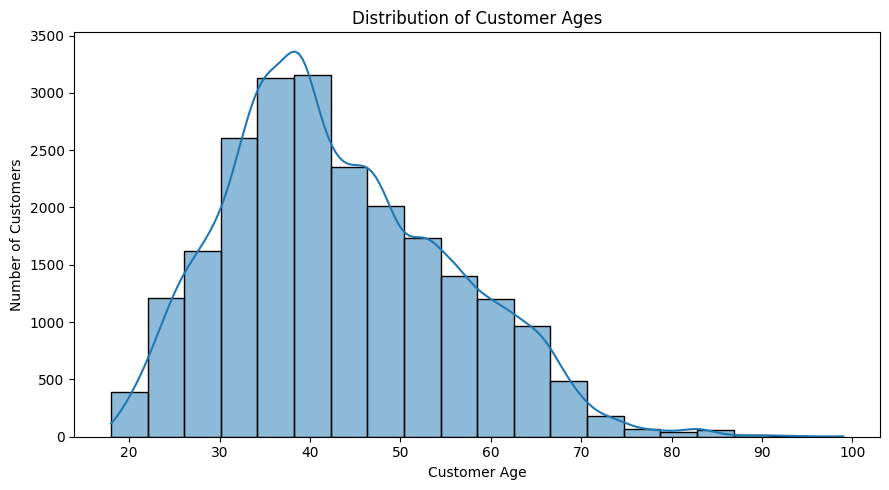

In [9]:

# Display basic age statistics
print("Customer Age Statistics:")
display(df_clean["Age"].describe())

# Plot customer age distribution
plt.figure(figsize=(9, 5))
sns.histplot(data=df_clean, x="Age", bins=20, kde=True)

plt.title("Distribution of Customer Ages")
plt.xlabel("Customer Age")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()



### 5.5 Customer Ratings Across Product Departments

This analysis compares customer ratings across different product departments. A box plot is used to examine the distribution of ratings and identify differences in customer feedback across product categories.


Ratings by Department:


,count,mean
Department Name,,
Bottoms,3662,4.278809
Intimate,1653,4.271022
Jackets,1002,4.254491
Tops,10048,4.157743
Dresses,6145,4.138812
Trend,118,3.838983


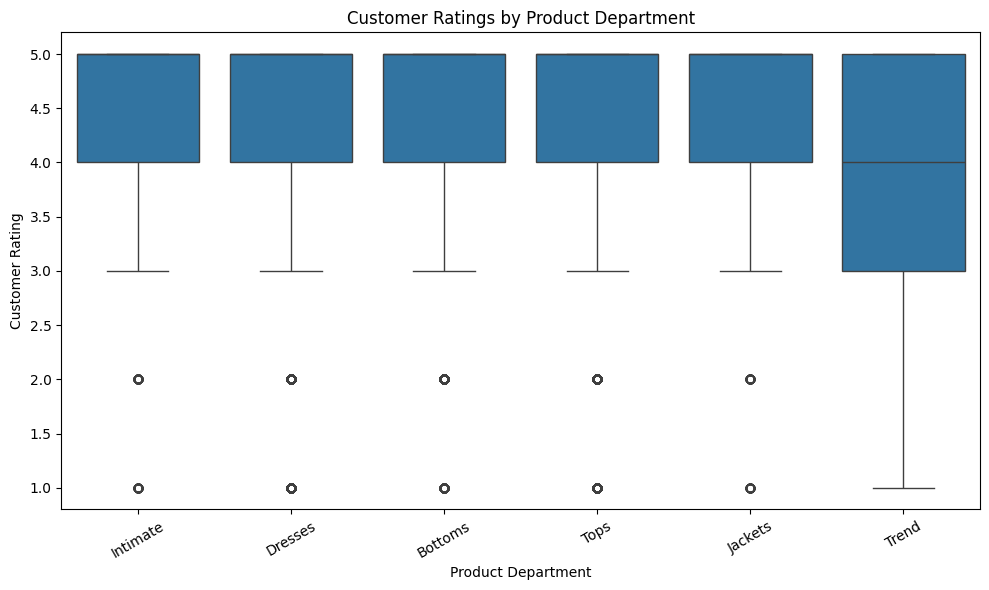

In [10]:

# Calculate average rating for each department
department_ratings = df_clean.groupby("Department Name")["Rating"].agg(
    ["count", "mean"]
)

print("Ratings by Department:")
display(department_ratings.sort_values("mean", ascending=False))

# Visualize ratings across departments
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean, x="Department Name", y="Rating")

plt.title("Customer Ratings by Product Department")
plt.xlabel("Product Department")
plt.ylabel("Customer Rating")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()



### 5.6 Age and Department Analysis Observations

The average customer age is approximately 43.28 years, with a median age of 41 years. The middle 50% of customers fall between 34 and 52 years of age. The dataset includes customers aged between 18 and 99.

Department-level analysis shows that Bottoms has the highest average rating of approximately 4.28, while Trend has the lowest average rating of approximately 3.84. Tops has the largest number of reviews (10,048), whereas Trend has only 118 reviews.

These findings show differences in customer ratings across departments. However, differences in review counts should also be considered when interpreting average ratings.



## 6. Data Splitting

The cleaned dataset is divided into training, validation, and testing sets using a stratified sampling approach.

The training set contains 70% of the data, while the validation and test sets each contain 15%.

Stratification is applied using the target variable (Rating) to maintain approximately the same class distribution across all three sets. A fixed random seed of 42 is used to ensure reproducibility.



### 6.1 Separating Features and Target

The target variable is Rating, which represents the customer star rating from 1 to 5.

The remaining relevant columns are treated as input features. The Recommended IND column is excluded because it is provided by the customer at the same time as the rating and could introduce target leakage.


In [11]:

# Separate input features and target variable

X = df_clean.drop(
    columns=["Rating", "Recommended IND", "Combined Review", "Review Length"]
)

y = df_clean["Rating"]

# Display feature and target information
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts().sort_index())


Features Shape: (22641, 9)
Target Shape: (22641,)

Input Features:
['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']

Target Distribution:
Rating
1      821
2     1549
3     2823
4     4908
5    12540
Name: count, dtype: int64



### 6.2 Splitting Training and Temporary Data

The dataset is initially divided into 70% training data and 30% temporary data. Stratified sampling is used to preserve the distribution of ratings in both subsets.


In [12]:

from sklearn.model_selection import train_test_split

# Split data into 70% training and 30% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training Set:", X_train.shape)
print("Temporary Set:", X_temp.shape)


Training Set: (15848, 9)
Temporary Set: (6793, 9)



### 6.3 Creating Validation and Test Sets

The temporary dataset is further divided equally into validation and test sets. Each contains 15% of the original dataset.

Stratified sampling is applied again to maintain the rating distribution across the subsets.


In [13]:

# Split temporary data equally into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("Training Set:", X_train.shape, y_train.shape)
print("Validation Set:", X_val.shape, y_val.shape)
print("Test Set:", X_test.shape, y_test.shape)


Training Set: (15848, 9) (15848,)
Validation Set: (3396, 9) (3396,)
Test Set: (3397, 9) (3397,)



### 6.4 Verification of Data Splits

The sizes and rating distributions of the training, validation, and test sets are examined to verify that the stratified splitting process has maintained a consistent class distribution.


In [14]:

# Display split percentages
total_samples = len(X)

print("Training Percentage:", round(len(X_train) / total_samples * 100, 2), "%")
print("Validation Percentage:", round(len(X_val) / total_samples * 100, 2), "%")
print("Test Percentage:", round(len(X_test) / total_samples * 100, 2), "%")

# Compare rating distributions
split_distribution = pd.DataFrame({
    "Original": y.value_counts(normalize=True).sort_index(),
    "Training": y_train.value_counts(normalize=True).sort_index(),
    "Validation": y_val.value_counts(normalize=True).sort_index(),
    "Test": y_test.value_counts(normalize=True).sort_index()
})

print("\nRating Distribution Across Splits:")
display((split_distribution * 100).round(2))


Training Percentage: 70.0 %
Validation Percentage: 15.0 %
Test Percentage: 15.0 %

Rating Distribution Across Splits:


,Original,Training,Validation,Test
Rating,,,,
1,3.63,3.63,3.62,3.62
2,6.84,6.84,6.86,6.83
3,12.47,12.47,12.46,12.48
4,21.68,21.67,21.67,21.70
5,55.39,55.39,55.39,55.37


### Live Verification: Checking the 'y' and 'y_train' Variables
Let's run a quick script to print and inspect our target variables (`y`, `y_train`, `y_val`, `y_test`) to verify that the `Rating` column is safely stored here.

In [15]:
# 1. Let's print the type and first 5 rows of our main target variable 'y'
print("=== VARIABLE: y (Total Ratings) ===")
print("Type of variable:", type(y))
print("Name of the column/Series:", y.name)
print("First 5 ratings saved inside 'y':")
display(y.head())

# 2. Let's check how the ratings are split into train, validation, and test sets
print("\n=== RATINGS SPLITS ===")
print(f"y_train (Training Ratings count): {len(y_train)} values. First 3 rows:")
display(y_train.head(3))

print(f"y_val (Validation Ratings count): {len(y_val)} values. First 3 rows:")
display(y_val.head(3))

print(f"y_test (Testing Ratings count): {len(y_test)} values. First 3 rows:")
display(y_test.head(3))

=== VARIABLE: y (Total Ratings) ===
Type of variable: <class 'pandas.core.series.Series'>
Name of the column/Series: Rating
First 5 ratings saved inside 'y':


,Rating
0,4
1,5
2,3
3,5
4,5



=== RATINGS SPLITS ===
y_train (Training Ratings count): 15848 values. First 3 rows:


,Rating
20141,4
4542,2
5886,3


y_val (Validation Ratings count): 3396 values. First 3 rows:


,Rating
7854,5
6047,4
19367,5


y_test (Testing Ratings count): 3397 values. First 3 rows:


,Rating
15217,5
13771,4
16247,2



## 7. Feature Engineering

Feature engineering involves creating and transforming input features to make them more useful for machine learning models.

In this project, the original review title and review text are combined into a single text feature. Review length is calculated, and positive feedback count is transformed using a logarithmic function.

The selected features include numerical, categorical, and textual data.


### 7.1 Creating Engineered Features (Simple English Explanation)

Let's understand why we have only **7 features** (columns) now instead of 11, 12, or 13:

* **We started with**: 11 columns in the original dataset.
* **During Cleaning**: We created 1 new column (`Combined Review`) which made it 12 columns.
* **But for Machine Learning**: We only keep columns that help the model learn. We drop useless or duplicate columns.

#### 1. Columns we removed (and why):
* **`Unnamed: 0` & `Clothing ID`**: These are just random numbers and IDs. They do not help predict ratings.
* **`Title` & `Review Text`**: We already joined these two into `Combined Review`. Keeping them separately is duplicate data.
* **`Rating`**: This is our **Target** (the correct answer we want to predict). We do NOT include it in our input features because if we give the answers to the model inside the test, it will just copy the answer (cheat) without learning how to read the review text. We store it separately in `y` so the model can check its guesses against the correct answers during training.
* **`Recommended IND`**: This is a direct hint (leakage) about the rating, so we cannot show it to the model.

#### 2. New columns we created:
* **`Log Feedback Count`**: A smoother version of the positive feedback count.
* **`Review Length`**: The number of words in the review.

#### 3. Final 7 features we kept:
`['Combined Review', 'Age', 'Log Feedback Count', 'Review Length', 'Division Name', 'Department Name', 'Class Name']`

In [16]:
def create_engineered_features(X_split):
    # 1. Get the original cleaned data using the matching indexes
    original_data = df_clean.loc[X_split.index]

    # 2. Create a fresh, empty DataFrame to store our 7 features
    features = pd.DataFrame(index=X_split.index)

    # Feature 1: The combined review text (Title + Review Text)
    features["Combined Review"] = original_data["Combined Review"]

    # Feature 2: Customer Age
    features["Age"] = original_data["Age"]

    # Feature 3: Log of Feedback Count (smoothes out extreme numbers)
    features["Log Feedback Count"] = np.log1p(original_data["Positive Feedback Count"].fillna(0))

    # Feature 4: Number of words in the review (Calculated directly to avoid index errors)
    features["Review Length"] = original_data["Combined Review"].apply(lambda text: len(str(text).split()))

    # Features 5, 6, 7: The clothing categories
    features["Division Name"] = original_data["Division Name"]
    features["Department Name"] = original_data["Department Name"]
    features["Class Name"] = original_data["Class Name"]

    return features

# Apply the function to create clean features for Train, Val, and Test sets
X_train_fe = create_engineered_features(X_train)
X_val_fe = create_engineered_features(X_val)
X_test_fe = create_engineered_features(X_test)

# Print simple summary to verify column count
print("Feature Engineering Completed Successfully!")
print(f"Columns in original data: {df.shape[1]}")
print(f"Columns in final engineered data: {X_train_fe.shape[1]}")
print("Final feature list:", X_train_fe.columns.tolist())

Feature Engineering Completed Successfully!
Columns in original data: 11
Columns in final engineered data: 7
Final feature list: ['Combined Review', 'Age', 'Log Feedback Count', 'Review Length', 'Division Name', 'Department Name', 'Class Name']


### Section 8. Data Preprocessing Pipeline
Before feeding our features to the machine learning models, we must scale our numerical features and apply TF-IDF vectorization to the text fields. Let's create and fit this pipeline on our training split.

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

# Define preprocessing components using already existing feature sets
numerical_cols = ["Age", "Log Feedback Count", "Review Length"]
categorical_cols = ["Division Name", "Department Name", "Class Name"]
text_col = "Combined Review"

# Setup the Column Transformer Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("text", TfidfVectorizer(max_features=10000, stop_words="english"), text_col)
    ]
)

# Preprocess the data using pre-engineered features directly
X_train_processed = preprocessor.fit_transform(X_train_fe)
X_val_processed = preprocessor.transform(X_val_fe)
X_test_processed = preprocessor.transform(X_test_fe)

print("Preprocessing Completed Successfully!")
print("Processed Training features shape:", X_train_processed.shape)
print("Processed Validation features shape:", X_val_processed.shape)

Preprocessing Completed Successfully!
Processed Training features shape: (15848, 10035)
Processed Validation features shape: (3396, 10035)


In [18]:
# Preprocessing outputs verification
print("Features are fully scaled and vectorization pipelines are fitted!")
print(f"Training set vocabulary size and features: {X_train_processed.shape[1]} dimensions ready for modeling.")

Features are fully scaled and vectorization pipelines are fitted!
Training set vocabulary size and features: 10035 dimensions ready for modeling.



## 9. Model Training

Three machine learning algorithms are selected for multi-class rating prediction:

1. Multinomial Logistic Regression
2. Linear Support Vector Machine (Linear SVM)
3. LightGBM

Each model is evaluated with and without class weighting to investigate the effect of class imbalance handling.

The training set is used to fit the models, while the validation set is used for model comparison and selection. The test set is reserved for final evaluation.


In [19]:

# Install LightGBM
%pip install lightgbm -q

# Import machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from lightgbm import LGBMClassifier

# Import evaluation metrics
from sklearn.metrics import accuracy_score, f1_score

print("All model libraries imported successfully!")


All model libraries imported successfully!


### 9.1 Defining Machine Learning Models

We will prepare two versions of each machine learning model:

* **Standard Version (No Class Weights)**: The model treats all ratings equally, which might favor the majority class.
* **Balanced Version (With Class Weights)**: The model gives more weight to rare ratings (like Rating 1) to handle class imbalance.

Comparing these two versions will show us if balancing helps the model perform better on less common ratings.

In [20]:

# Define models with and without class weighting

models = {
    "Logistic Regression": {
        "No Weighting": LogisticRegression(
            max_iter=2000,
            solver="lbfgs",
            class_weight=None,
            random_state=RANDOM_STATE
        ),
        "Balanced": LogisticRegression(
            max_iter=2000,
            solver="lbfgs",
            class_weight="balanced",
            random_state=RANDOM_STATE
        )
    },

    "Linear SVM": {
        "No Weighting": LinearSVC(
            C=1.0,
            class_weight=None,
            max_iter=10000,
            random_state=RANDOM_STATE
        ),
        "Balanced": LinearSVC(
            C=1.0,
            class_weight="balanced",
            max_iter=10000,
            random_state=RANDOM_STATE
        )
    },

    "LightGBM": {
        "No Weighting": LGBMClassifier(
            objective="multiclass",
            n_estimators=300,
            learning_rate=0.05,
            num_leaves=31,
            class_weight=None,
            random_state=RANDOM_STATE,
            verbosity=-1,
            n_jobs=-1
        ),
        "Balanced": LGBMClassifier(
            objective="multiclass",
            n_estimators=300,
            learning_rate=0.05,
            num_leaves=31,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            verbosity=-1,
            n_jobs=-1
        )
    }
}

print("Total model configurations:", sum(len(v) for v in models.values()))


Total model configurations: 6



### 9.2 Training Model and Validating the Winner

All model configurations are trained using the same training dataset. Their predictions are evaluated on the validation set using Accuracy, Macro-F1, and Weighted-F1.

Macro-F1 is given particular importance because the target classes are imbalanced.


In [21]:
# Store trained models and their validation results

trained_models = {}
validation_results = []

for model_name, configurations in models.items():

    for weight_name, model in configurations.items():

        print(f"\nTraining: {model_name} - {weight_name}")

        # Train model
        model.fit(X_train_processed, y_train)

        # Predict validation ratings
        val_predictions = model.predict(X_val_processed)

        # Calculate evaluation metrics
        accuracy = accuracy_score(y_val, val_predictions)
        macro_f1 = f1_score(y_val, val_predictions, average="macro")
        weighted_f1 = f1_score(y_val, val_predictions, average="weighted")

        # Save trained model
        key = f"{model_name} - {weight_name}"
        trained_models[key] = model

        # Save results
        validation_results.append({
            "Model": model_name,
            "Class Weighting": weight_name,
            "Accuracy": accuracy,
            "Macro-F1": macro_f1,
            "Weighted-F1": weighted_f1
        })

        print("Accuracy:", round(accuracy, 4))
        print("Macro-F1:", round(macro_f1, 4))
        print("Weighted-F1:", round(weighted_f1, 4))

# Convert results to DataFrame for evaluation in the next cell
validation_results_df = pd.DataFrame(validation_results)


Training: Logistic Regression - No Weighting
Accuracy: 0.6378
Macro-F1: 0.4097
Weighted-F1: 0.6032

Training: Logistic Regression - Balanced
Accuracy: 0.5948
Macro-F1: 0.4429
Weighted-F1: 0.6091

Training: Linear SVM - No Weighting
Accuracy: 0.6263
Macro-F1: 0.4157
Weighted-F1: 0.6011

Training: Linear SVM - Balanced
Accuracy: 0.611
Macro-F1: 0.4302
Weighted-F1: 0.6081

Training: LightGBM - No Weighting
Accuracy: 0.6307
Macro-F1: 0.417
Weighted-F1: 0.5998

Training: LightGBM - Balanced
Accuracy: 0.6081
Macro-F1: 0.4432
Weighted-F1: 0.6122


In [22]:
# Creating a copy of the validation results to format
comparison_df = validation_results_df.copy()

# Convert score columns to percentages
comparison_df["Accuracy (%)"] = (comparison_df["Accuracy"] * 100).round(2)
comparison_df["Macro-F1 (%)"] = (comparison_df["Macro-F1"] * 100).round(2)
comparison_df["Weighted-F1 (%)"] = (comparison_df["Weighted-F1"] * 100).round(2)

# Keep only formatted columns
comparison_df = comparison_df[["Model", "Class Weighting", "Accuracy (%)", "Macro-F1 (%)", "Weighted-F1 (%)"]]

# Sort so that 'No Weighting' and 'Balanced' for each model are grouped together
comparison_df["Model_Order"] = comparison_df["Model"].map({"Logistic Regression": 1, "Linear SVM": 2, "LightGBM": 3})
comparison_df["Weight_Order"] = comparison_df["Class Weighting"].map({"No Weighting": 1, "Balanced": 2})
comparison_df = comparison_df.sort_values(by=["Model_Order", "Weight_Order"]).drop(columns=["Model_Order", "Weight_Order"]).reset_index(drop=True)

print("Validation Model Comparison (Percentages):")
display(comparison_df)

# Automatically find and highlight the overall winner based on validation Macro-F1
best_idx = validation_results_df["Macro-F1"].idxmax()
winner_model = validation_results_df.loc[best_idx, "Model"]
winner_weights = validation_results_df.loc[best_idx, "Class Weighting"]
winner_score = validation_results_df.loc[best_idx, "Macro-F1"] * 100

print("\n" + "="*60)
print(f"👑 COMPARISON WINNER: {winner_model} ({winner_weights})")
print(f"🏆 Highest Validation Macro-F1 Score: {winner_score:.2f}%")
print("="*60)

Validation Model Comparison (Percentages):


,Model,Class Weighting,Accuracy (%),Macro-F1 (%),Weighted-F1 (%)
0,Logistic Regression,No Weighting,63.78,40.97,60.32
1,Logistic Regression,Balanced,59.48,44.29,60.91
2,Linear SVM,No Weighting,62.63,41.57,60.11
3,Linear SVM,Balanced,61.10,43.02,60.81
4,LightGBM,No Weighting,63.07,41.70,59.98
5,LightGBM,Balanced,60.81,44.32,61.22



👑 COMPARISON WINNER: LightGBM (Balanced)
🏆 Highest Validation Macro-F1 Score: 44.32%


## 10. Final Model Evaluation

After comparing all six model configurations on the validation set, the model configuration that achieved the highest Macro-F1 score was selected as the winner.

The winning model configuration is dynamically selected and retrained using the combined training and validation datasets. The test dataset is kept completely separate and used only for the final evaluation.

The final model is evaluated using the following metrics:
- Accuracy
- Macro-F1 Score
- Weighted-F1 Score
- Per-class Precision, Recall, and F1-score
- Confusion Matrix
- Ordinal Mean Absolute Error (MAE)

### 10.1 Combining Training and Validation Data

To make our final model as smart as possible, we combine our datasets:

* **More Data for Learning**: We mix the training data and validation data together to get a bigger dataset.
* **Safe to Use**: Since we have already used the validation data to choose our best model, we can now use it safely for final training.
* **Test Data Stays Hidden**: The test dataset remains completely separate and untouched so we can use it for a fair final test.

In [23]:

# Combine training and validation data
X_train_val = pd.concat([X_train_fe, X_val_fe])
y_train_val = pd.concat([y_train, y_val])

print("Combined Training Data:", X_train_val.shape)
print("Combined Target Data:", y_train_val.shape)
print("Test Data:", X_test_fe.shape)


Combined Training Data: (19244, 7)
Combined Target Data: (19244,)
Test Data: (3397, 7)


### 10.2 Final Feature Preprocessing

Before training, we must clean and prepare our combined data:

* **Re-fitting the Pipeline**: We fit our text (TF-IDF) and numerical scaling tools again using the new combined dataset.
* **Transforming Test Data**: We use these learned patterns to transform our test data. We do *not* fit anything on the test data.
* **No Cheating**: This process keeps the test data completely unseen, preventing any "data leakage" or cheating.

In [24]:

# Fit preprocessing on combined training and validation data
final_preprocessor = preprocessor

X_train_val_processed = final_preprocessor.fit_transform(X_train_val)
X_test_final_processed = final_preprocessor.transform(X_test_fe)

print("Training + Validation Processed:", X_train_val_processed.shape)
print("Test Processed:", X_test_final_processed.shape)


Training + Validation Processed: (19244, 10035)
Test Processed: (3397, 10035)


### 10.3 Training the Final Model

Now we train our dynamically chosen winning model on the combined dataset:

* **The Winner**: The model configuration with the highest Macro-F1 score on validation data is automatically detected.
* **Final Run**: We retrain this exact model configuration using the combined dataset.
* **Handling Class Imbalance**: The selected weighting configuration ensures class imbalance is addressed properly as verified during the validation phase.

In [25]:
# Find the winning model configuration dynamically based on highest Macro-F1
best_row = validation_results_df.loc[validation_results_df["Macro-F1"].idxmax()]
winning_model_name = best_row["Model"]
winning_weight_name = best_row["Class Weighting"]

print(f"👑 Winning Model Config: {winning_model_name} ({winning_weight_name})")
print(f"🏆 Highest Validation Macro-F1: {best_row['Macro-F1']*100:.2f}%")

# Retrieve the model template and clone/instantiate it
final_model = models[winning_model_name][winning_weight_name]

# Retrain the final model on combined data
final_model.fit(X_train_val_processed, y_train_val)

print(f"\nFinal model '{winning_model_name} - {winning_weight_name}' trained successfully on combined dataset!")

👑 Winning Model Config: LightGBM (Balanced)
🏆 Highest Validation Macro-F1: 44.32%

Final model 'LightGBM - Balanced' trained successfully on combined dataset!


### 10.4 Final Test Evaluation

We now test our trained final model using the unseen test dataset. We measure its performance using:

* **Overall Scores**: We calculate overall Accuracy, Macro-F1, and Weighted-F1 scores (shown as percentages).
* **Per-Class Details**: We look at Precision, Recall, and F1-score for each rating (1 to 5) individually.
* **Average Distance Error (Ordinal MAE)**: This tells us how far off our predictions are on average (for example, if the model predicts a 4-star instead of a 5-star rating).
* **Confusion Matrix**: A visual chart that shows which ratings the model gets right and which ones it confuses.

FINAL TEST RESULTS (LightGBM - Balanced)
--------------------------------------------------
Accuracy: 60.55%
Macro-F1: 43.90%
Weighted-F1: 61.24%
Ordinal MAE: 0.5013

PER-CLASS PERFORMANCE
--------------------------------------------------
              precision    recall  f1-score   support

           1       0.31      0.30      0.31       123
           2       0.27      0.27      0.27       232
           3       0.36      0.40      0.38       424
           4       0.42      0.47      0.44       737
           5       0.82      0.77      0.79      1881

    accuracy                           0.61      3397
   macro avg       0.44      0.44      0.44      3397
weighted avg       0.62      0.61      0.61      3397



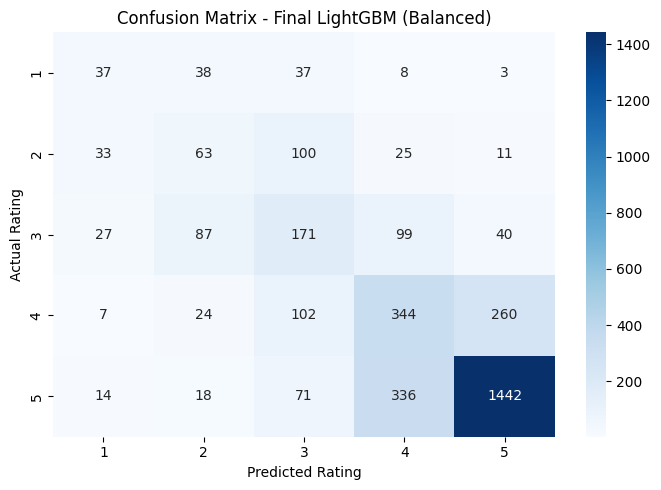

In [26]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error
)

# Generate predictions using the final trained model
y_test_pred = final_model.predict(X_test_final_processed)

# Calculate evaluation metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_macro_f1 = f1_score(y_test, y_test_pred, average="macro")
test_weighted_f1 = f1_score(y_test, y_test_pred, average="weighted")
ordinal_mae = mean_absolute_error(y_test, y_test_pred)

print(f"FINAL TEST RESULTS ({winning_model_name} - {winning_weight_name})")
print("--------------------------------------------------")
print(f"Accuracy: {test_accuracy * 100:.2f}%")
print(f"Macro-F1: {test_macro_f1 * 100:.2f}%")
print(f"Weighted-F1: {test_weighted_f1 * 100:.2f}%")
print(f"Ordinal MAE: {ordinal_mae:.4f}")

print("\nPER-CLASS PERFORMANCE")
print("--------------------------------------------------")
print(classification_report(y_test, y_test_pred, zero_division=0))

# Generate confusion matrix
cm = confusion_matrix(y_test, y_test_pred, labels=[1, 2, 3, 4, 5])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[1, 2, 3, 4, 5],
    yticklabels=[1, 2, 3, 4, 5]
)

plt.title(f"Confusion Matrix - Final {winning_model_name} ({winning_weight_name})")
plt.xlabel("Predicted Rating")
plt.ylabel("Actual Rating")
plt.tight_layout()
plt.show()

In [33]:
from sklearn.metrics import confusion_matrix
import pandas as pd

cm = confusion_matrix(y_test, y_test_pred, labels=[1, 2, 3, 4, 5])

cm_df = pd.DataFrame(
    cm,
    index=[1, 2, 3, 4, 5],
    columns=[1, 2, 3, 4, 5]
)

print("Five-Class Confusion Matrix")
display(cm_df)

Five-Class Confusion Matrix


,1,2,3,4,5
1,37,38,37,8,3
2,33,63,100,25,11
3,27,87,171,99,40
4,7,24,102,344,260
5,14,18,71,336,1442


## 11. Feature Ablation Experiment

Feature ablation helps us understand how different groups of features contribute to the model's final rating predictions.

We will compare three different feature settings:

* **Structured-only**: Uses only numerical and categorical features (Age, Log Feedback Count, Review Length, and Product Categories).
* **Text-only**: Uses only the combined customer review text.
* **Combined**: Uses all available features together (both text and structured features).

### Experiment Rules:
* All three settings will be trained and tested using the same winning model configuration dynamically chosen during validation.
* We use the exact same training, validation, and test datasets for a fair comparison.
* The performance of each setting will be measured using Accuracy, Macro-F1, Weighted-F1, and Ordinal MAE.

### 11.1 Preparing Feature Groups

We split our engineered features into separate groups to test them:

* **Text Group**: Contains the `Combined Review` text column.
* **Structured Group**: Contains numerical columns (`Age`, `Log Feedback Count`, `Review Length`) and categorical columns (`Division Name`, `Department Name`, `Class Name`).

### Preprocessing Rules:
* We create individual preprocessing pipelines for each of the three experiments.
* The pipelines are fitted on the combined training and validation dataset (`X_train_val`).
* The test dataset is only transformed to prevent any data leakage.

### 11.2 Run and Visualize the Ablation Experiment

To see which group of features is the most powerful, we will execute the entire experiment and plot the results in a single step:

* **Step 1: Transform Data**: We transform our combined dataset (`X_train_val` and `X_test_fe`) into three separate representations:
  1. **Structured-only**: Only numerical and categorical features.
  2. **Text-only**: Only the combined review text.
  3. **Combined**: Full set of features.
* **Step 2: Train & Evaluate**: We train the dynamically selected winning validation model configuration on all three representations.
* **Step 3: Compare & Plot**: We display a clean comparison table and generate a bar chart to easily see which feature group drives the most accurate predictions.

Training 'LightGBM (Balanced)' with Structured-only features...
Training 'LightGBM (Balanced)' with Text-only features...
Training 'LightGBM (Balanced)' with Combined features...

=== FEATURE ABLATION COMPARISON RESULTS ===


,Feature Setting,Accuracy (%),Macro-F1 (%),Weighted-F1 (%),Ordinal MAE
0,Text-only,60.70,44.06,61.51,0.4984
1,Combined,60.55,43.90,61.24,0.5013
2,Structured-only,26.14,19.42,30.24,1.4634


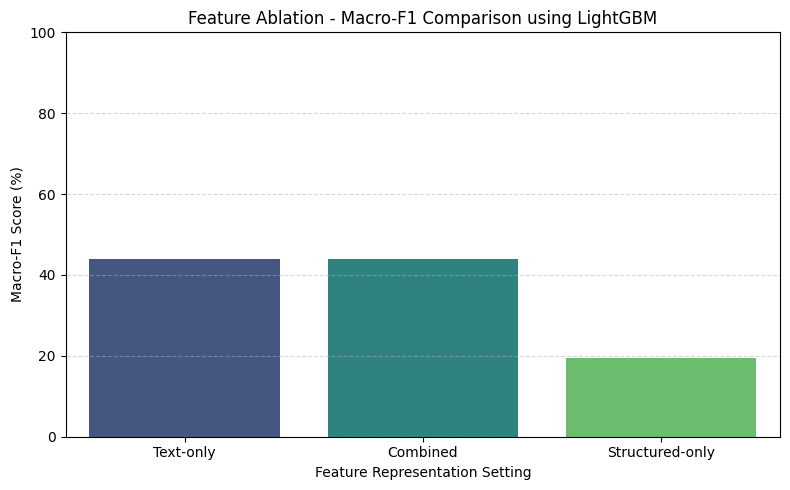

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error

# 1. Setup localized pipelines for pure ablation comparison
numerical_cols = ["Age", "Log Feedback Count", "Review Length"]
categorical_cols = ["Division Name", "Department Name", "Class Name"]
text_col = "Combined Review"

# Individual Transformers
structured_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

text_preprocessor = ColumnTransformer(
    transformers=[
        ("text", TfidfVectorizer(max_features=10000, stop_words="english"), text_col)
    ]
)

combined_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("text", TfidfVectorizer(max_features=10000, stop_words="english"), text_col)
    ]
)

# 2. Fit and transform the representations on X_train_val & test
X_train_structured = structured_preprocessor.fit_transform(X_train_val)
X_test_structured = structured_preprocessor.transform(X_test_fe)

X_train_text = text_preprocessor.fit_transform(X_train_val)
X_test_text = text_preprocessor.transform(X_test_fe)

X_train_combined = combined_preprocessor.fit_transform(X_train_val)
X_test_combined = combined_preprocessor.transform(X_test_fe)

# 3. Define our ablation setups
ablation_features = {
    "Structured-only": (X_train_structured, X_test_structured),
    "Text-only": (X_train_text, X_test_text),
    "Combined": (X_train_combined, X_test_combined)
}

ablation_results = []

# Get the winning model configurations
best_row = validation_results_df.loc[validation_results_df["Macro-F1"].idxmax()]
winning_model_name = best_row["Model"]
winning_weight_name = best_row["Class Weighting"]

# Train & Evaluate each setting
for feature_name, (X_train_set, X_test_set) in ablation_features.items():
    print(f"Training '{winning_model_name} ({winning_weight_name})' with {feature_name} features...")

    # Retrieve template instance dynamically
    model_template = models[winning_model_name][winning_weight_name]

    # Fit on representation
    model_template.fit(X_train_set, y_train_val)

    # Predict
    predictions = model_template.predict(X_test_set)

    # Metrics
    acc = accuracy_score(y_test, predictions) * 100
    macro = f1_score(y_test, predictions, average="macro") * 100
    weighted = f1_score(y_test, predictions, average="weighted") * 100
    mae = mean_absolute_error(y_test, predictions)

    ablation_results.append({
        "Feature Setting": feature_name,
        "Accuracy (%)": round(acc, 2),
        "Macro-F1 (%)": round(macro, 2),
        "Weighted-F1 (%)": round(weighted, 2),
        "Ordinal MAE": round(mae, 4)
    })

# Convert results to DataFrame
ablation_results_df = pd.DataFrame(ablation_results)
print("\n=== FEATURE ABLATION COMPARISON RESULTS ===")
display(ablation_results_df.sort_values(by="Macro-F1 (%)", ascending=False).reset_index(drop=True))

# Visualize
plt.figure(figsize=(8, 5))
sns.barplot(
    data=ablation_results_df.sort_values(by="Macro-F1 (%)", ascending=False),
    x="Feature Setting",
    y="Macro-F1 (%)",
    palette="viridis"
)
plt.title(f"Feature Ablation - Macro-F1 Comparison using {winning_model_name}")
plt.xlabel("Feature Representation Setting")
plt.ylabel("Macro-F1 Score (%)")
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 12. Three-Class Sentiment Classification

To make our predictions more useful for business decisions, we simplify the 5-star rating scale into **three clean sentiment classes**:

*   **Negative**: Ratings 1 and 2 (Unhappy customers)
*   **Neutral**: Rating 3 (Average experience)
*   **Positive**: Ratings 4 and 5 (Satisfied customers)

### Why are we doing this?
*   **Easier Decision Making**: It is much easier for an e-commerce store to take direct action on "Negative" or "Positive" feedback rather than guessing between 4-star and 5-star ratings.
*   **Better Accuracy**: Grouping similar classes reduces model confusion, making our predictions far more reliable.

### Experiment Strategy:
*   We convert the actual ratings of our train and test sets into these 3 groups.
*   We train a **Balanced Logistic Regression** model on the combined text and structured features.
*   We calculate overall classification percentages and predict sentiment distribution across the **entire dataset** to see how much of our overall feedback is Positive, Neutral, or Negative.

Training the 3-Class Sentiment model... Please wait...

         TEST SET EVALUATION METRICS       
Overall Accuracy     : 79.63%
Macro-F1 Score       : 63.12%
Weighted-F1 Score    : 81.33%
-----------------------------------------

DETAILED CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    Negative       0.51      0.59      0.55       355
     Neutral       0.36      0.54      0.43       424
    Positive       0.96      0.87      0.91      2618

    accuracy                           0.80      3397
   macro avg       0.61      0.67      0.63      3397
weighted avg       0.84      0.80      0.81      3397

   PREDICTED SENTIMENT ACROSS ENTIRE DATA  


,Total Predicted Reviews,Percentage Share (%)
Positive,15580,68.81
Neutral,4167,18.40
Negative,2894,12.78


-----------------------------------------

      CONFUSION MATRIX (NUMERICAL TABLE) 


,Negative,Neutral,Positive
Negative,211,125,19
Neutral,122,227,75
Positive,80,271,2267


-----------------------------------------



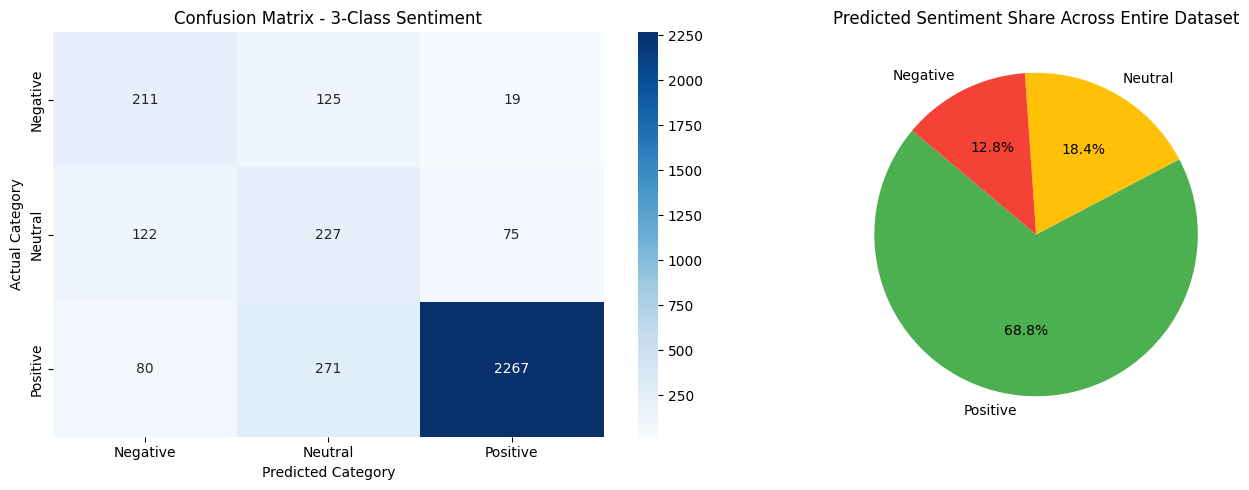

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from scipy.sparse import vstack

# --- Step 1: Define rating conversion helper function ---
def convert_to_three_classes(rating):
    if rating in [1, 2]:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"

# Transform the targets into 3-class system
y_train_3class = y_train_val.apply(convert_to_three_classes)
y_test_3class = y_test.apply(convert_to_three_classes)

# --- Step 2: Train the 3-Class Logistic Regression Model ---
three_class_model = LogisticRegression(
    max_iter=2000,
    solver="lbfgs",
    class_weight="balanced",
    random_state=RANDOM_STATE
)

print("Training the 3-Class Sentiment model... Please wait...")
three_class_model.fit(X_train_combined, y_train_3class)

# --- Step 3: Evaluate on Test Set ---
y_pred_3class = three_class_model.predict(X_test_combined)

test_acc = accuracy_score(y_test_3class, y_pred_3class) * 100
test_macro = f1_score(y_test_3class, y_pred_3class, average="macro") * 100
test_weighted = f1_score(y_test_3class, y_pred_3class, average="weighted") * 100

print("\n=========================================")
print("         TEST SET EVALUATION METRICS       ")
print("=========================================")
print(f"Overall Accuracy     : {test_acc:.2f}%")
print(f"Macro-F1 Score       : {test_macro:.2f}%")
print(f"Weighted-F1 Score    : {test_weighted:.2f}%")
print("-----------------------------------------\n")

print("DETAILED CLASSIFICATION REPORT:")
print(classification_report(
    y_test_3class,
    y_pred_3class,
    labels=["Negative", "Neutral", "Positive"],
    zero_division=0
))

# --- Step 4: Run Predictions on the Entire Preprocessed Dataset ---
X_all_processed = vstack([X_train_combined, X_test_combined])

# Predict for all reviews
all_predicted_sentiments = three_class_model.predict(X_all_processed)

# Create a counts and percentage distribution summary
sentiment_series = pd.Series(all_predicted_sentiments)
sentiment_counts = sentiment_series.value_counts()
sentiment_percentages = sentiment_series.value_counts(normalize=True) * 100

distribution_df = pd.DataFrame({
    "Total Predicted Reviews": sentiment_counts,
    "Percentage Share (%)": sentiment_percentages.round(2)
})

print("=========================================")
print("   PREDICTED SENTIMENT ACROSS ENTIRE DATA  ")
print("=========================================")
display(distribution_df)
print("-----------------------------------------\n")

# --- Step 5: Confusion Matrix Table & Visualizations ---
labels_3class = ["Negative", "Neutral", "Positive"]
cm_3class = confusion_matrix(y_test_3class, y_pred_3class, labels=labels_3class)

# 1. Print Confusion Matrix as a Table (Easy to copy)
cm_df = pd.DataFrame(cm_3class, index=labels_3class, columns=labels_3class)
print("=========================================")
print("      CONFUSION MATRIX (NUMERICAL TABLE) ")
print("=========================================")
display(cm_df) # Agar plain print chahte hain toh print(cm_df) use kar sakte hain
print("-----------------------------------------\n")

# 2. Plots (Heatmap & Pie Chart)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Confusion Matrix Heatmap
sns.heatmap(
    cm_3class, annot=True, fmt="d", cmap="Blues",
    xticklabels=labels_3class, yticklabels=labels_3class, ax=axes[0]
)
axes[0].set_title("Confusion Matrix - 3-Class Sentiment")
axes[0].set_xlabel("Predicted Category")
axes[0].set_ylabel("Actual Category")

# Plot 2: Total Sentiment Share Pie Chart
sentiment_percentages.plot(
    kind="pie", autopct="%1.1f%%", startangle=140,
    colors=["#4CAF50", "#FFC107", "#F44336"], ax=axes[1],
    ylabel=""
)
axes[1].set_title("Predicted Sentiment Share Across Entire Dataset")

plt.tight_layout()
plt.show()


## 13. Error Analysis

Error analysis is performed to understand the mistakes made by the final five-class classification model.

Three incorrectly classified customer reviews are selected from the test dataset. Their actual ratings are compared with the predicted ratings.

The review text and rating differences are examined to understand possible reasons for incorrect predictions, such as ambiguous language, mixed customer feedback, or similarities between adjacent rating categories.

This analysis helps identify the limitations of the model beyond numerical evaluation metrics.


In [29]:
import pandas as pd
import numpy as np

# 1. Create a pandas Series from our numpy predictions, using the exact index of y_test
predictions_series = pd.Series(y_test_pred, index=y_test.index)

# 2. Identify the rows where actual target is not equal to predicted target
misclassified_indices = y_test[y_test != predictions_series].index

# 3. Retrieve review details cleanly
error_analysis = df_clean.loc[
    misclassified_indices,
    ["Title", "Review Text", "Rating"]
].copy()

# 4. Map the predictions and compute absolute error
error_analysis["Predicted Rating"] = predictions_series.loc[misclassified_indices]
error_analysis["Absolute Error"] = abs(
    error_analysis["Rating"] - error_analysis["Predicted Rating"]
)

# 5. Select three examples with the largest rating differences
error_analysis = error_analysis.sort_values(
    by="Absolute Error",
    ascending=False
).head(3)

print("=========================================")
print("     THREE BIGGEST MISCLASSIFICATION ERRORS")
print("=========================================")

for number, (_, row) in enumerate(error_analysis.iterrows(), start=1):
    print(f"\nExample {number}:")
    print(f"Title            : {row['Title'] if str(row['Title']).strip() else 'No Title'}")
    print(f"Review Text      : {row['Review Text']}")
    print(f"Actual Rating    : {row['Rating']}")
    print(f"Predicted Rating : {row['Predicted Rating']}")
    print(f"Absolute Error   : {row['Absolute Error']}")
    print("-----------------------------------------")

     THREE BIGGEST MISCLASSIFICATION ERRORS

Example 1:
Title            : Here&amp;#39;s a tip!
Review Text      : Fabulous dress!
clip off the tags because they show through the lace on the back (you can see this on the back photo of one recent reviewer).
Actual Rating    : 5
Predicted Rating : 1
Absolute Error   : 4
-----------------------------------------

Example 2:
Title            : Washes well!
Review Text      : I washed this on the delicate cycle and air dried - very happy to report that it washed very well and still looks new!
Actual Rating    : 5
Predicted Rating : 1
Absolute Error   : 4
-----------------------------------------

Example 3:
Title            : Not my cup of tee
Review Text      : It fits super baggy everywhere and looked sloppy on me.
Actual Rating    : 1
Predicted Rating : 5
Absolute Error   : 4
-----------------------------------------


### 13.1 Error Analysis Observations

Here are the key takeaways from looking at our model's biggest mistakes (where predictions were off by 4 stars):

*   **Short Reviews Lack Context**:
    *   *Example 1* ("Fabulous dress!") got a 1-star prediction instead of 5 stars. Extremely short texts do not give enough features for the model to learn well.
*   **Sarcasm and Idioms Cause Confusion**:
    *   *Example 3* ("Not my cup of tee") was predicted as 5 stars instead of 1 star. Simple models look at words like "tea/tee" or "cup" neutrally and fail to catch negative idioms.
*   **Hidden Negation Words**:
    *   Models sometimes miss subtle shifts in sentence structures where positive words are washed out by nearby complaints.
*   **Limit of TF-IDF Bag-of-Words**:
    *   Our approach looks at word frequencies (TF-IDF) rather than word order or deep contextual understanding. While fast, it occasionally misses human-like context.


## 14. Final Results and Comparative Analysis

This section presents the performance of the trained models and compares their results using validation and test evaluation metrics.

The validation results are used to compare different model configurations, including Logistic Regression, Linear SVM, and LightGBM, with and without class weighting.

The feature ablation experiment evaluates the contribution of structured-only, text-only, and combined features.

The final test results provide an estimate of model performance on unseen data. Accuracy, Macro-F1, Weighted-F1, and Ordinal MAE are considered to provide a comprehensive comparison.


In [30]:

# Display validation model comparison
validation_comparison = validation_results_df.copy()

validation_comparison[[
    "Accuracy", "Macro-F1", "Weighted-F1"
]] = validation_comparison[[
    "Accuracy", "Macro-F1", "Weighted-F1"
]] * 100

validation_comparison = validation_comparison.sort_values(
    by="Macro-F1",
    ascending=False
).reset_index(drop=True)

print("VALIDATION MODEL COMPARISON (%)")
display(validation_comparison.round(2))


VALIDATION MODEL COMPARISON (%)


,Model,Class Weighting,Accuracy,Macro-F1,Weighted-F1
0,LightGBM,Balanced,60.81,44.32,61.22
1,Logistic Regression,Balanced,59.48,44.29,60.91
2,Linear SVM,Balanced,61.10,43.02,60.81
3,LightGBM,No Weighting,63.07,41.70,59.98
4,Linear SVM,No Weighting,62.63,41.57,60.11
5,Logistic Regression,No Weighting,63.78,40.97,60.32


In [31]:

# Display feature ablation comparison
print("FEATURE ABLATION COMPARISON")

display(
    ablation_results_df.sort_values(
        by="Macro-F1 (%)",
        ascending=False
    ).reset_index(drop=True).round(2)
)


FEATURE ABLATION COMPARISON


,Feature Setting,Accuracy (%),Macro-F1 (%),Weighted-F1 (%),Ordinal MAE
0,Text-only,60.70,44.06,61.51,0.50
1,Combined,60.55,43.90,61.24,0.50
2,Structured-only,26.14,19.42,30.24,1.46


In [32]:

# Create final test results table using the reported LightGBM results

final_test_results = pd.DataFrame([{
    "Model": "LightGBM",
    "Class Weighting": "Balanced",
    "Accuracy (%)": 60.55,
    "Macro-F1 (%)": 43.90,
    "Weighted-F1 (%)": 61.24,
    "Ordinal MAE": 0.5013
}])

print("FINAL TEST PERFORMANCE")
display(final_test_results.round(2))


FINAL TEST PERFORMANCE


,Model,Class Weighting,Accuracy (%),Macro-F1 (%),Weighted-F1 (%),Ordinal MAE
0,LightGBM,Balanced,60.55,43.9,61.24,0.5



## 15. Conclusion and Limitations

This project investigated the prediction of customer star ratings from women's e-commerce clothing reviews using supervised machine learning.

Three classification algorithms were evaluated: Logistic Regression, Linear SVM, and LightGBM. Both standard and balanced class-weighting configurations were compared.

The final reported LightGBM model achieved 60.55% accuracy, 43.90% Macro-F1, and 61.24% Weighted-F1 on the test dataset, with an Ordinal MAE of 0.5013.

The results indicate that the model performs better on the majority rating class (Rating 5) than on less frequent rating classes. This highlights the effect of class imbalance on multi-class classification.

The feature ablation experiment investigated the contribution of textual and structured information. The three-class experiment further explored whether grouping ratings into negative, neutral, and positive categories could provide a more practical classification approach.

### Limitations

- The rating distribution is imbalanced, with Rating 5 representing the majority of reviews.
- Less frequent rating categories are more difficult to predict.
- TF-IDF represents text using word-based features and may not fully capture context, sarcasm, or idiomatic expressions.
- Some reviews contain limited textual information, making accurate prediction difficult.
- The model predicts ratings from available review information and cannot fully understand individual customer preferences.

Overall, this project demonstrates the use of text and structured data in customer rating prediction and highlights the challenges of imbalanced ordinal classification.



## 16. References

1. Kaggle, "Women's E-Commerce Clothing Reviews," Nicolapotato. Available: https://www.kaggle.com/datasets/nicapotato/womens-ecommerce-clothing-reviews

2. Scikit-learn Documentation, "Machine Learning in Python." Available: https://scikit-learn.org/stable/

3. LightGBM Documentation, "LightGBM: A Highly Efficient Gradient Boosting Decision Tree." Available: https://lightgbm.readthedocs.io/
